# Project 13: Named Entity Recognition for Biomedical Texts using Transformer Language Models

**COMP9444 26T3 group project, Team HAHA. Single submission notebook.**

| Section | Rubric item (marks) | Owner |
|---|---|---|
| 1 Introduction and problem statement | Introduction / motivation (1) | Yuchen Li |
| 2 Data sources | Data sources (1) | Yuchen Li |
| 3 Exploratory data analysis | EDA (3) | Yuchen Li, Alex Shen |
| 4 Models and methods | Models / methods (3) | Alex Shen (protocol), Bai Li (BioBERT), Yuanquan Jin (PubMedBERT), Chongli Chen (DAPT) |
| 5 Results | Results (3) | Alex Shen |
| 6 Discussion and error analysis | Discussion (2) | Alex Shen, Chongli Chen |
| 7 Conclusion | | all |

**How to read this notebook.** Every cell has been executed and its output is saved, so nothing needs to be re-run.
All scores come from one unified fine-tuning framework (the `ner/` package in this repository): same data files,
same strict IOB2 entity-level metric, same hyper-parameters, three seeds per model. Section 5 builds **one** results
table from the saved per-seed metric files. The command that regenerates those files is in the appendix.

> Draft rule: write each section's text in the markdown cells below; do not paste numbers by hand. Every number must
> come from a cell in this notebook.

## 0. Setup
Runs locally from the repository root, or on Google Colab (the cell clones the repository first).

In [1]:
import os, sys, json, glob
from pathlib import Path
from collections import Counter

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not Path("ner").exists():
    !git clone -b final-submission https://github.com/lofty14/bert-ner-baseline.git
    %cd bert-ner-baseline
    !pip -q install transformers==5.22.0 accelerate==1.15.0 seqeval==1.2.2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(".").resolve()
sys.path.insert(0, str(ROOT))
pd.set_option("display.precision", 2)
print("repo root:", ROOT)

repo root: /Users/chonglichen/UNSW/COMP9444/group_project


## 1. Introduction and problem statement
*Owner: Yuchen Li. Rubric: clearly define the problem statement or purpose of the project.*

Points to cover (replace this list with prose):
- Biomedical NER: find disease mentions in PubMed abstracts and tag them at the token level (BIO scheme).
- Why it matters: literature search, knowledge-base curation, downstream relation extraction.
- Why it is hard: abbreviations, multi-word and nested-looking spans, many diseases unseen in training.
- Project objectives (from the course brief): (1) fine-tune BioBERT and PubMedBERT, (2) improve generalisation with a
  domain-adaptation technique, (3) evaluate with precision, recall and F1.
- Our questions: how much do biomedical pre-trained encoders gain over general BERT under one fair protocol, and can a
  small amount of domain-adaptive pre-training (DAPT) recover part of that gain cheaply?

## 2. Data sources
*Owner: Yuchen Li. Rubric: data sources are clearly documented and described.*

- **NCBI Disease corpus** (Doğan et al., 2014): 793 PubMed abstracts, disease mentions annotated by 12 annotators
  in pairs. Official split: 593 / 100 / 100 abstracts (train / dev / test).
- We use the sentence-level CoNLL release (`spyysalo/ncbi-disease`, the version used by BioBERT). The loader
  downloads the files once and checks each file against a pinned SHA-256 hash.
- Labels: `O`, `B-Disease`, `I-Disease`.
- DAPT corpus (section 4.5): about 29,000 PubMed abstracts collected by the team; checked for overlap with the
  NCBI test abstracts.

In [2]:
from ner.data import load_ncbi, LABELS
splits, audit = load_ncbi(audit=False)
print("labels:", LABELS)
for name, rows in splits.items():
    print(f"{name:>10}: {len(rows):5d} sentences")

labels: ['O', 'B-Disease', 'I-Disease']
     train:  5432 sentences
validation:   923 sentences
      test:   940 sentences


## 3. Exploratory data analysis
*Owners: Yuchen Li, Alex Shen. Rubric (3 marks): properties, number of classes, pre-processing, and challenging aspects
of the data.*

In [3]:
def entities(tags):
    """Strict IOB2 spans as (start, end) token offsets, end exclusive."""
    spans, start = [], None
    for i, t in enumerate(tags + ["O"]):
        if t == "B-Disease" or t == "O" or (t == "I-Disease" and start is None):
            if start is not None:
                spans.append((start, i))
                start = None
            if t == "B-Disease":
                start = i
    return spans

rows = []
for name, data in splits.items():
    n_tok = sum(len(t) for t, _ in data)
    tag_counts = Counter(tag for _, tags in data for tag in tags)
    ents = [(toks, s) for toks, tags in data for s in entities(tags)]
    rows.append({
        "split": name,
        "sentences": len(data),
        "tokens": n_tok,
        "mentions": len(ents),
        "sentences with >=1 mention (%)": 100 * sum(bool(entities(tags)) for _, tags in data) / len(data),
        "O tokens (%)": 100 * tag_counts["O"] / n_tok,
        "B tokens (%)": 100 * tag_counts["B-Disease"] / n_tok,
        "I tokens (%)": 100 * tag_counts["I-Disease"] / n_tok,
        "mean mention length (tokens)": np.mean([e - s for _, (s, e) in ents]),
    })
eda = pd.DataFrame(rows).set_index("split")
eda

,sentences,tokens,mentions,sentences with >=1 mention (%),O tokens (%),B tokens (%),I tokens (%),mean mention length (tokens)
split,,,,,,,,
train,5432,136086,5145,53.94,91.72,3.78,4.50,2.19
validation,923,23969,787,52.98,92.17,3.28,4.55,2.39
test,940,24497,960,57.34,91.64,3.92,4.44,2.13


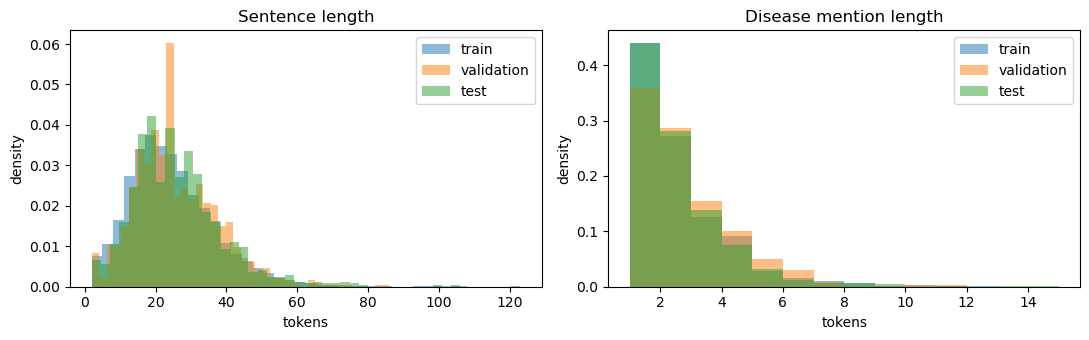

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, data in splits.items():
    axes[0].hist([len(t) for t, _ in data], bins=40, alpha=0.5, density=True, label=name)
    lens = [e - s for _, tags in data for s, e in entities(tags)]
    axes[1].hist(lens, bins=range(1, 16), alpha=0.5, density=True, label=name)
axes[0].set(title="Sentence length", xlabel="tokens", ylabel="density")
axes[1].set(title="Disease mention length", xlabel="tokens", ylabel="density")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

In [5]:
def mention_texts(data):
    return [" ".join(toks[s:e]) for toks, tags in data for s, e in entities(tags)]

train_mentions = set(m.lower() for m in mention_texts(splits["train"]))
for name in ["validation", "test"]:
    ms = mention_texts(splits[name])
    unseen = [m for m in ms if m.lower() not in train_mentions]
    print(f"{name}: {len(ms)} mentions, {100 * len(unseen) / len(ms):.1f}% never appear as a mention in train")

print()
print("Most frequent training mentions:")
print(Counter(mention_texts(splits["train"])).most_common(15))

abbrev = [m for m in mention_texts(splits["train"]) if m.isupper() and len(m) <= 6]
print()
print(f"Upper-case abbreviations among training mentions: {len(abbrev)} "
      f"({100 * len(abbrev) / len(mention_texts(splits['train'])):.1f}%), e.g. {Counter(abbrev).most_common(8)}")

validation: 787 mentions, 35.2% never appear as a mention in train
test: 960 mentions, 37.7% never appear as a mention in train

Most frequent training mentions:
[('DM', 120), ('DMD', 109), ('APC', 91), ('ALD', 86), ('PWS', 75), ('WAS', 63), ('myotonic dystrophy', 57), ('G6PD deficiency', 57), ('HD', 55), ('PKU', 52), ('aniridia', 50), ('Duchenne muscular dystrophy', 44), ('breast cancer', 42), ('VHL', 40), ('FAP', 39)]

Upper-case abbreviations among training mentions: 1520 (29.5%), e.g. [('DM', 120), ('DMD', 109), ('APC', 91), ('ALD', 86), ('PWS', 75), ('WAS', 63), ('HD', 55), ('PKU', 52)]


In [6]:
# Leakage check between splits (exact duplicate sentences).
sent = {name: set(" ".join(t) for t, _ in data) for name, data in splits.items()}
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    print(f"{a} / {b}: {len(sent[a] & sent[b])} identical sentences")

train / validation: 5 identical sentences
train / test: 1 identical sentences
validation / test: 1 identical sentences


**Observations (to write up):**
- Three classes, heavily imbalanced: almost all tokens are `O`.
- Mentions are short but multi-word mentions are common; boundary errors are the main risk (see section 6).
- A large share of test mentions never occurs in train, so the model must generalise beyond memorising names.
- Abbreviations (e.g. `DM`, `APC`) are ambiguous between gene and disease.
- Pre-processing: sentence-level CoNLL; words are split into sub-words by each model's tokenizer and only the
  first sub-word of each word is labelled (section 4.1).

## 4. Models and methods
*Rubric (3 marks): models / methods are judiciously chosen and appropriately applied; if building on previous work,
identify the source and clearly delineate which parts are our own work.*

| Part | Source | Our own work |
|---|---|---|
| Pre-trained encoders | Hugging Face checkpoints (below), pinned to a commit | choice of models, casing checks |
| Token classification head, Trainer | Hugging Face `transformers` | label alignment, metric, model selection, seeds |
| Metric | `seqeval` (strict IOB2) | wrapper and checks against our own entity counts |
| DAPT (masked-LM) | standard MLM objective (Gururangan et al., 2020) | PubMed corpus collection, leak check, training and evaluation |

In [7]:
import ast

def show_source(path, names):
    """Print the source of selected top-level functions/classes without importing the module."""
    text = Path(path).read_text()
    tree = ast.parse(text)
    lines = text.splitlines()
    for node in tree.body:
        if getattr(node, "name", None) in names:
            print("\n".join(lines[node.lineno - 1:node.end_lineno]))
            print()

print(Path("ner/models.py").read_text())

"""Model registry. Every checkpoint is pinned to a Hugging Face commit."""

import json

from transformers import AutoTokenizer

MODELS = {
    # `google-bert/bert-base-cased` is the canonical repo that `bert-base-cased` redirects to.
    "bert": {
        "checkpoint": "google-bert/bert-base-cased",
        "revision": "cd5ef92a9fb2f889e972770a36d4ed042daf221e",
        "lowercase": False,
    },
    # BioBERT v1.2 ships no tokenizer_config.json, so BertTokenizer would default to
    # do_lower_case=True on a cased vocab. We force case preservation.
    "biobert": {
        "checkpoint": "dmis-lab/biobert-base-cased-v1.2",
        "revision": "67c9c25b46986521ca33df05d8540da1210b3256",
        "lowercase": False,
    },
    "pubmedbert": {
        "checkpoint": "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract",
        "revision": "d673b8835373c6fa116d6d8006b33d48734e305d",
        "lowercase": True,
    },
}


def load_tokenizer(key):
    spec = MODELS[key]
    tokenizer = AutoT

### 4.1 Unified fine-tuning protocol
*Owner: Alex Shen.* Describe: token classification with a linear head, first-sub-word labelling, maximum length,
optimiser and learning rate, epochs, batch size, dev-set model selection on strict F1, seeds 1/2/3, fp32.

In [8]:
show_source("ner/train.py", ["encode", "to_word_level", "seqeval_scores", "compute_metrics"])

def encode(rows, tokenizer, max_length, split):
    """Tokenize words; label only the first sub-token of each word (others -100).

    Self-check: the kept labels must equal the original word labels for every sentence.
    """
    encoded = tokenizer(
        [tokens for tokens, _ in rows], truncation=True, max_length=max_length, is_split_into_words=True,
    )
    features, bad, truncated = [], [], 0
    for i, (tokens, tags) in enumerate(rows):
        word_ids = encoded.word_ids(batch_index=i)
        truncated += len(word_ids) >= max_length
        labels, previous = [], None
        for word_id in word_ids:
            if word_id is None or word_id == previous:
                labels.append(-100)
            else:
                labels.append(LABEL2ID[tags[word_id]])
            previous = word_id
        if [ID2LABEL[x] for x in labels if x != -100] != tags:
            bad.append(i)
        feature = {key: encoded[key][i] for key in encoded.keys()}
        feature["labels"] = l

In [9]:
cfg = json.load(open("dapt/results/metrics/bert_seed1.json"))
print(json.dumps({k: cfg[k] for k in ["config", "training_args", "selection"]}, indent=1)[:3000])

{
 "config": {
  "model": "bert",
  "seed": 1,
  "lr": 2e-05,
  "epochs": 3,
  "batch_size": 8,
  "eval_batch_size": null,
  "warmup_ratio": 0.0,
  "weight_decay": 0.01,
  "max_length": 512,
  "early_stopping_patience": 0,
  "save_total_limit": 2,
  "keep_checkpoints": false,
  "save_model": false,
  "train_limit": null,
  "eval_limit": null,
  "logging_steps": 50,
  "precision": "fp32",
  "select_metric": "strict_f1",
  "no_test_history": false,
  "data_dir": "data/ncbi_disease",
  "init_from": null,
  "label": "bert",
  "output_dir": "runs/v2/bert/seed1",
  "warmup_steps": 0,
  "steps_per_epoch": 679,
  "total_steps": 2037
 },
 "training_args": {
  "output_dir": "runs/v2/bert/seed1/checkpoints",
  "per_device_train_batch_size": 8,
  "num_train_epochs": 3,
  "max_steps": -1,
  "learning_rate": 2e-05,
  "lr_scheduler_type": "linear",
  "lr_scheduler_kwargs": null,
  "warmup_steps": 0,
  "optim": "adamw_torch",
  "optim_args": null,
  "weight_decay": 0.01,
  "adam_beta1": 0.9,
  "adam_b

### 4.2 BERT baseline
General-domain `bert-base-cased`: the reference point for both biomedical models and for DAPT.

### 4.3 BioBERT
*Owner: Bai Li.* BioBERT v1.2 (`dmis-lab/biobert-base-cased-v1.2`): BERT further pre-trained on PubMed and PMC.
Explain why it is a good fit, and the casing fix in the model registry.

### 4.4 PubMedBERT
*Owner: Yuanquan Jin.* `microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract`: trained from scratch on PubMed with
its own biomedical vocabulary. Explain the difference from BioBERT (vocabulary, from-scratch training).

### 4.5 Domain-adaptive pre-training (DAPT)
*Owner: Chongli Chen.* Continue masked-language-model training of plain BERT on about 29,000 PubMed abstracts, then
fine-tune for NER with exactly the same protocol as 4.1. Only the starting weights change. Tests the brief's
objective "improve generalisation using domain adaptation".

In [10]:
show_source("ner/dapt.py", ["make_windows", "MLMCollator"])
d = json.load(open("dapt/results/bert_dapt_3ep.dapt.json"))
print("corpus:", d["corpus"]["documents"], "documents,", f'{d["corpus"]["train_tokens"]:,}', "training tokens")
print("MLM config:", {k: d["config"][k] for k in ["epochs", "batch_size", "lr", "max_length", "mlm_probability"]})
print("validation perplexity: %.2f -> %.2f" % (d["valid_perplexity"]["initial"], d["valid_perplexity"]["final"]))
print("training time: %.1f h" % (d["seconds"]["total"] / 3600))

def make_windows(texts, tokenizer, max_length):
    """Non-overlapping [CLS] + pieces + [SEP] windows of at most max_length tokens."""
    size = max_length - 2
    features = []
    for start in range(0, len(texts), 1000):
        ids = tokenizer(texts[start:start + 1000], add_special_tokens=False, truncation=False,
                        verbose=False)["input_ids"]
        for doc in ids:
            for i in range(0, len(doc), size):
                piece = [tokenizer.cls_token_id] + doc[i:i + size] + [tokenizer.sep_token_id]
                features.append({"input_ids": piece,
                                 "special_tokens_mask": [1] + [0] * (len(piece) - 2) + [1]})
    return features

class MLMCollator:
    """Dynamic masking for training windows; windows that already carry labels are only padded."""

    def __init__(self, tokenizer, mlm_probability):
        self.mlm = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm_probability=mlm_probability)
        self.pad_id =

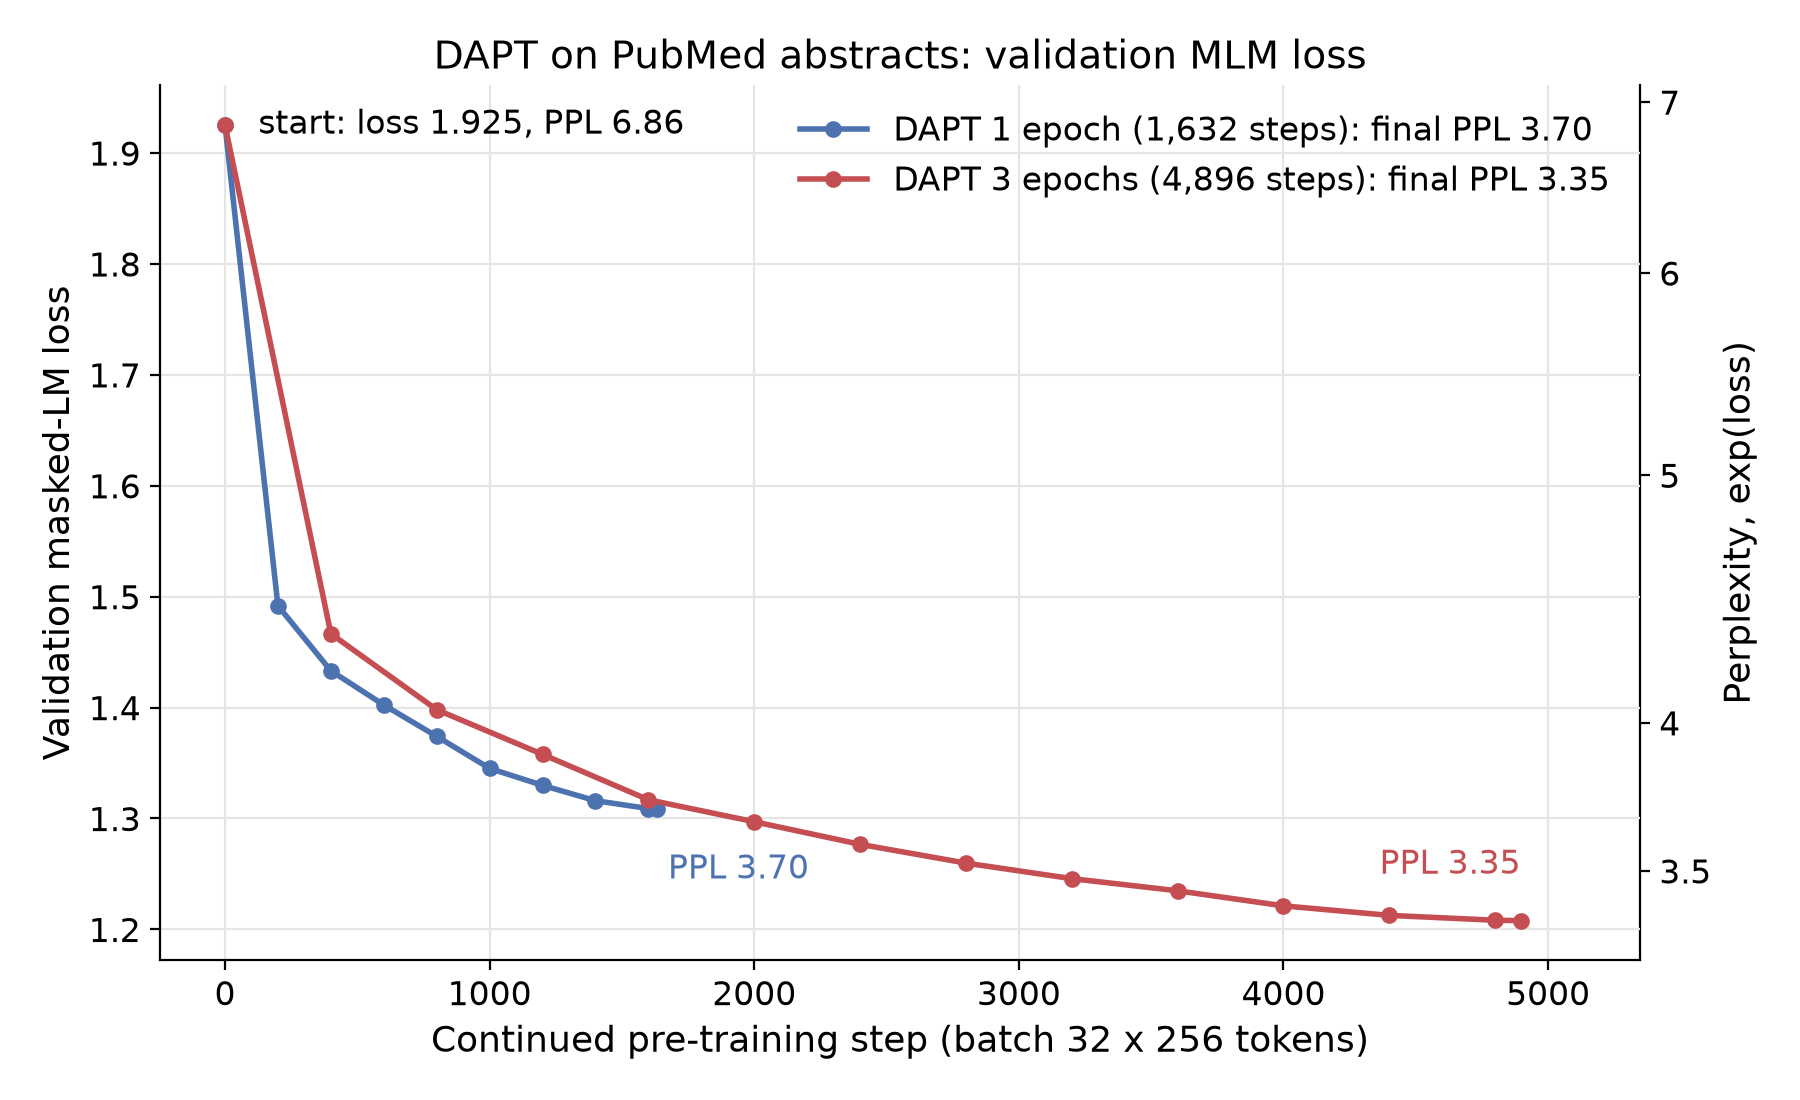

In [11]:
from IPython.display import Image, display
display(Image("dapt/figs/mlm_valid_loss.png", width=600))

## 5. Results
*Owner: Alex Shen. Rubric (3 marks): results clearly shown and evaluated with appropriate metrics; graphs; comparison
with previous methods / state of the art.*

The table is built from the per-seed metric files. Test scores are taken at the epoch selected on the dev set.

In [12]:
METRIC_DIRS = ["results/metrics", "dapt/results/metrics"]   # per-seed JSON written by ner.train
EXPECTED = ["bert", "biobert", "pubmedbert", "bert+dapt1ep", "bert+dapt3ep"]

runs = []
for d in METRIC_DIRS:
    for f in sorted(glob.glob(f"{d}/*_seed*.json")):
        label = Path(f).stem.rsplit("_seed", 1)[0]
        if label.startswith("control"):
            continue
        m = json.load(open(f))
        s = m["test"]["strict"]
        runs.append({"model": label, "seed": m["seed"], "P": 100 * s["precision"],
                     "R": 100 * s["recall"], "F1": 100 * s["f1"]})
runs = pd.DataFrame(runs).drop_duplicates(["model", "seed"])

missing = [m for m in EXPECTED if m not in set(runs.model)]
if missing:
    print("MISSING per-seed metrics for:", missing, "-> add their JSON files to results/metrics/")

summary = runs.groupby("model")[["P", "R", "F1"]].agg(["mean", "std"])
summary["seeds"] = runs.groupby("model").seed.count()
summary = summary.reindex([m for m in EXPECTED if m in summary.index])
summary

MISSING per-seed metrics for: ['biobert', 'pubmedbert'] -> add their JSON files to results/metrics/


P            R           F1       seeds
               mean   std   mean   std   mean   std      
model                                                    
bert          84.26  0.32  86.63  0.87  85.43  0.51     3
bert+dapt1ep  83.58  0.82  86.91  0.64  85.21  0.68     3
bert+dapt3ep  83.22  0.06  87.12  1.30  85.12  0.63     3

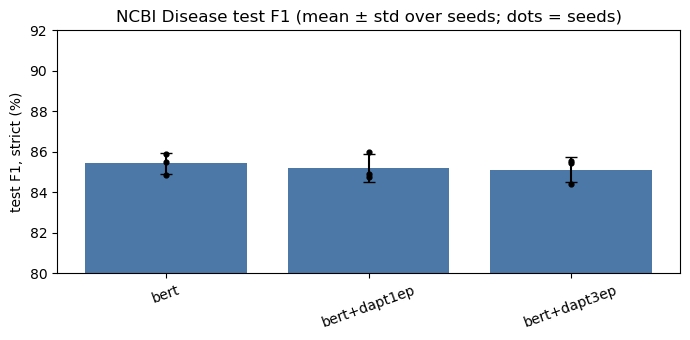

In [13]:
order = list(summary.index)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(order, summary[("F1", "mean")], yerr=summary[("F1", "std")], capsize=4, color="#4C78A8")
for i, m in enumerate(order):
    ax.scatter([i] * (runs.model == m).sum(), runs[runs.model == m].F1, color="black", s=12, zorder=3)
ax.set(ylabel="test F1, strict (%)", title="NCBI Disease test F1 (mean ± std over seeds; dots = seeds)")
ax.set_ylim(80, 92)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Three-model comparison as presented (single run per model).** These are the test-set scores shown on the
presentation slide (runs by Yuanquan Jin and Bai Li). They are single runs, so they are not directly comparable
with the 3-seed means above; for example BERT is 85.28 here and 85.43 ± 0.51 in the unified 3-seed table.
TODO: replace with per-seed metric files from the unified framework if they are available before submission.

,P,R,F1,token acc
model,,,,
BERT-base-cased,82.62,88.13,85.28,98.39
BioBERT,85.97,90.00,87.94,98.61
PubMedBERT,85.63,89.38,87.46,98.58


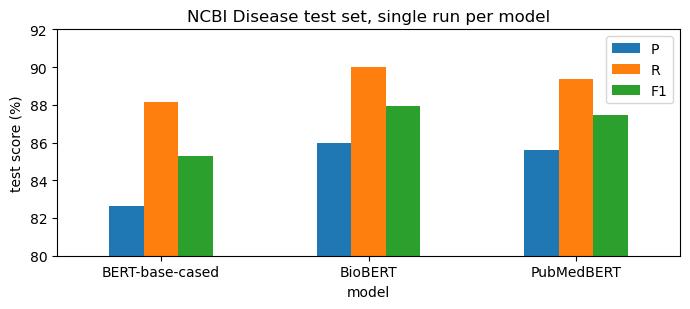

In [14]:
presented = pd.DataFrame(
    [["BERT-base-cased", 82.62, 88.13, 85.28, 98.39],
     ["BioBERT", 85.97, 90.00, 87.94, 98.61],
     ["PubMedBERT", 85.63, 89.38, 87.46, 98.58]],
    columns=["model", "P", "R", "F1", "token acc"]).set_index("model")
display(presented)
ax = presented[["P", "R", "F1"]].plot.bar(figsize=(7, 3.2), ylim=(80, 92), rot=0)
ax.set(ylabel="test score (%)", title="NCBI Disease test set, single run per model")
plt.tight_layout()
plt.show()

**Comparison with published results.** Fill in from the papers, and say how their protocol differs from ours
(e.g. number of runs, train+dev training, metric):

| Model | Published F1 on NCBI Disease | Source | Ours (mean ± std) |
|---|---|---|---|
| BERT | TODO | Lee et al., 2020 | from table above |
| BioBERT v1.1 | 89.71 | Lee et al., 2020, Table 6 | 87.94 (single run) |
| PubMedBERT | 87.82 | Gu et al., 2021 | 87.46 (single run) |

## 6. Discussion and error analysis
*Owners: Alex Shen, Chongli Chen. Rubric (2 marks): insight into performance, strengths, weaknesses, limitations,
future work.*

In [15]:
text = Path("dapt/results/error_analysis_dapt3ep.md").read_text()
print(text.split("### Stable differences")[0])

Entity-level error analysis, `bert+dapt3ep` vs `bert`, split `test`, seeds 1, 2, 3. Strict IOB2 entities (as seqeval mode='strict'); counts are checked against each run's metrics.json. 940 sentences, 960 gold entities.

FP boundary = predicted entity overlaps a gold entity but the span differs; FP spurious = no overlap with any gold entity. FN boundary = gold entity overlaps a predicted entity; FN missed = no overlap. One predicted span can overlap two gold spans (and vice versa), so FP boundary and FN boundary need not be equal. P / R / F1 in the `all` rows are pooled over seeds (micro), so they can differ in the second decimal from the mean over seeds in results.md. `tokens` = start-end (end exclusive) token offsets.

### Totals over seeds

| label | seed | TP | FP | FP boundary | FP spurious | FN | FN boundary | FN missed | P | R | F1 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| bert | all | 2495 | 466 | 234 | 232 | 385 | 212 | 173 | 84.26 | 86.63 | 85.43 |
| ber

Points to cover:
- Biomedical pre-training vs general BERT: size of the gain, and where it comes from (vocabulary, abbreviations).
- DAPT: the model did adapt (perplexity 6.9 to 3.4), yet NER F1 did not change beyond seed noise. Likely reasons:
  the corpus is small (about 10 M tokens vs billions for BioBERT/PubMedBERT); the NCBI training set already
  supplies the in-domain signal NER needs.
- Error types: boundary errors vs spurious / missed mentions; ambiguous abbreviations.
- Limitations: one dataset, three seeds, one hyper-parameter setting, small DAPT corpus.
- Future work: larger DAPT corpus or task-adaptive pre-training, other datasets (BC5CDR), CRF head, LLM prompting baseline.

## 7. Conclusion
One paragraph: what we built, the main numbers, the answer to each question in section 1.

## References
- Doğan, R. I., Leaman, R., Lu, Z. (2014). NCBI disease corpus. *Journal of Biomedical Informatics*.
- Devlin, J. et al. (2019). BERT. *NAACL*.
- Lee, J. et al. (2020). BioBERT. *Bioinformatics*.
- Gu, Y. et al. (2021). Domain-specific language model pretraining for biomedical NLP (PubMedBERT). *ACM HEALTH*.
- Gururangan, S. et al. (2020). Don't stop pretraining. *ACL*.

## Appendix: how the saved metrics were produced
Not executed here (about 13 minutes per run on an Apple M-series GPU). From the repository root:

```bash
python audit_ncbi_splits.py --no-hf --conll_dir data/ncbi_disease
python -m ner.sweep --models bert biobert pubmedbert --seeds 1 2 3 --runs_dir runs/final
python -m ner.aggregate runs/final --out runs/final/results.md
python -m ner.dapt --model bert --epochs 3 --output_dir runs_dapt/bert_dapt_3ep
python -m ner.sweep --models bert --seeds 1 2 3 --init_from runs_dapt/bert_dapt_3ep/model --label bert+dapt3ep
```